# 07 · Correlation, WOE Transformation & A/B Test Design

**Objective:** finish model preparation (multicollinearity check and WOE transformation of the shortlisted features) and size an A/B test for a pricing change.

**Bottom line:** **the eight shortlisted features are ready for modeling**: no pair is highly correlated (max |ρ| = 0.49, income vs. loan amount, and loan amount is already dropped), and all eight are WOE-transformed with no missing values, reproducing the notebook 06 IVs exactly. **A test of a 1-point APR cut for grade B needs ~8,400 offers per group** to detect a 30% → 32% take-up lift (5% significance, 80% power), about two months at 10,000 offers a month, with early delinquency and risk-adjusted return as guardrails.

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from lending_db import get_connection, IMAGE_DIR

con = get_connection()
pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
import numpy as np

## 1. Multicollinearity check
Two features carrying the same information make logistic-regression coefficients **unstable** (they can even flip sign), which breaks a scorecard's business logic and its **adverse-action reasons**. **Spearman** correlation is used because it is rank-based and robust to outliers such as DTI = 999. Threshold: |ρ| > 0.7.

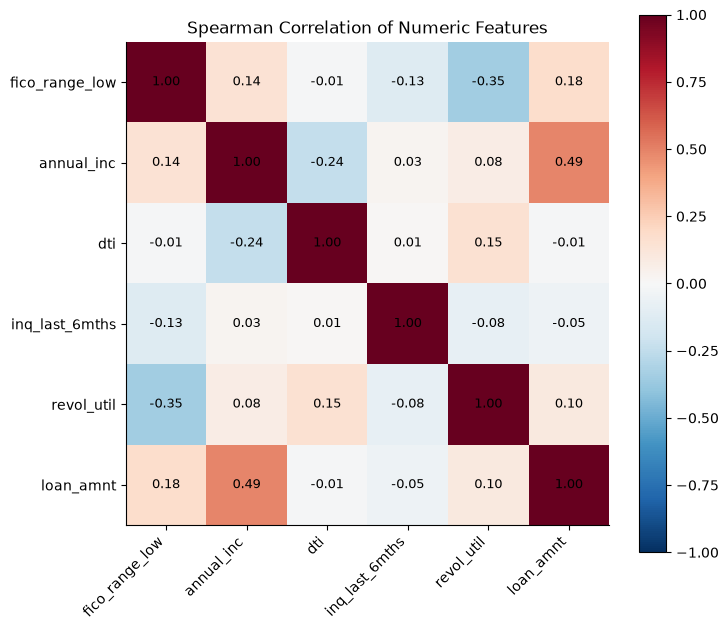

,level_0,level_1,rho,abs_rho
11,annual_inc,loan_amnt,0.49,0.49
4,fico_range_low,revol_util,-0.35,0.35
8,annual_inc,dti,-0.24,0.24
5,fico_range_low,loan_amnt,0.18,0.18
16,dti,revol_util,0.15,0.15


In [2]:
num = con.sql("""
SELECT fico_range_low, annual_inc, dti, inq_last_6mths, revol_util, loan_amnt
FROM cohort
""").df()

corr = num.corr(method="spearman")

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.grid(False)
fig.colorbar(im)
ax.set_title("Spearman Correlation of Numeric Features")
fig.tight_layout()
fig.savefig(IMAGE_DIR / "feature_correlation.png", dpi=150)
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
             .rename("rho").reset_index().assign(abs_rho=lambda d: d["rho"].abs())
             .sort_values("abs_rho", ascending=False))
pairs.head(5).round(2)

* **No pair exceeds 0.7.** The strongest is income vs. loan amount (0.49): higher earners borrow more. Loan amount was already dropped for low IV.
* **FICO vs. revolving utilization: −0.35.** Utilization is part of the FICO formula ("amounts owed"), which is why it adds little information beyond FICO (IV 0.013).
* **Income vs. DTI: −0.24** is partly mechanical: income is DTI's denominator.
* Pairwise correlation can miss a feature explained by a *combination* of others; a VIF check covers that case.

## 2. WOE transformation
Each loan's bin is replaced by that bin's WOE. This turns text features into numbers, gives missing values and outliers their own value without imputation, puts every feature on the same log-odds scale, and makes each feature **linear in the log-odds of default**, the form logistic regression expects.

Binning rules carried over from notebook 06, plus one fix: bins with fewer than 300 loans are merged into the largest bin (the 2-loan missing-DTI bin otherwise gets an extreme WOE of −1.78).

In [3]:
def calc_iv(df, bin_col):
    t = df.groupby(bin_col, observed=True, dropna=False)["bad_flag"].agg(n_bad="sum", n_total="count")
    t["n_good"]    = t["n_total"] - t["n_bad"]
    t["dist_good"] = t["n_good"] / t["n_good"].sum()
    t["dist_bad"]  = t["n_bad"] / t["n_bad"].sum()
    t["woe"]       = np.log(t["dist_good"] / t["dist_bad"])
    t["iv_bin"]    = (t["dist_good"] - t["dist_bad"]) * t["woe"]
    return t, t["iv_bin"].sum()


def make_bins(s, kind, min_size=300):
    """Bin one feature; tiny bins (e.g. 2 loans with missing DTI) are merged into the largest bin."""
    if kind == "quantile":
        bins = pd.qcut(s, 5, duplicates="drop").astype(object)
    elif kind == "count":
        bins = s.clip(upper=3).astype(object)              # 0 / 1 / 2 / 3+
    else:
        bins = s.astype(object)
    bins = bins.where(bins.notna(), "Missing").astype(str)   # missing values become their own labelled bin
    sizes = bins.value_counts()
    return bins.where(~bins.isin(sizes[sizes < min_size].index), sizes.idxmax())


model = con.sql("""
SELECT issue_date, fico_range_low, annual_inc, dti, inq_last_6mths,
       home_ownership, verification_status, purpose, emp_length, bad_flag
FROM cohort
""").df()

features = {
    "fico_range_low": "quantile", "annual_inc": "quantile", "dti": "quantile", "inq_last_6mths": "count",
    "home_ownership": "category", "verification_status": "category", "purpose": "category", "emp_length": "category",
}

woe_tables, rows = {}, []
for col, kind in features.items():
    model[col + "_bin"] = make_bins(model[col], kind)
    table, iv = calc_iv(model, col + "_bin")
    model[col + "_woe"] = model[col + "_bin"].map(table["woe"])
    woe_tables[col] = table
    rows.append({"feature": col, "n_bins": len(table), "iv": iv,
                 "woe_min": table["woe"].min(), "woe_max": table["woe"].max()})

woe_cols = [c + "_woe" for c in features]
assert model[woe_cols].notna().all().all(), "every loan must receive a WOE value"
pd.DataFrame(rows).round(4)

,feature,n_bins,iv,woe_min,woe_max
0,fico_range_low,5,0.1349,-0.3564,0.7793
1,annual_inc,5,0.0619,-0.3429,0.3794
2,dti,5,0.0539,-0.3429,0.2943
3,inq_last_6mths,4,0.0431,-0.4710,0.1698
4,home_ownership,3,0.0440,-0.2035,0.2394
5,verification_status,3,0.0401,-0.2471,0.2731
6,purpose,11,0.0216,-0.5583,0.2161
7,emp_length,12,0.0215,-0.4582,0.1315


* All eight IVs match notebook 06 to within 0.0001. Merging the 2-loan missing-DTI bin removes its extreme −1.78 WOE (DTI's minimum WOE is now −0.34).
* Every feature has both negative and positive WOE: the overall bad rate is a weighted average of the bins, so some bins must sit above it and some below.
* WOE vs. bad rate is monotonic for FICO (below): the bin with WOE ≈ 0 has a bad rate equal to the portfolio average.

In [4]:
check = (model.groupby("fico_range_low_woe")["bad_flag"].agg(n_loans="size", bad_rate="mean")
              .sort_index())
check.round(4)

,n_loans,bad_rate
fico_range_low_woe,,
-0.356384,89931,0.1947
-0.22286,115024,0.1746
-0.00905,84595,0.1459
0.258307,76732,0.1156
0.779341,79461,0.072


In [5]:
# Save the model-ready table for the PD model (development / OOT split by issue_date)
from lending_db import DATA_DIR
con.register("model_woe", model[["issue_date", "bad_flag"] + woe_cols])
con.sql(f"COPY model_woe TO '{DATA_DIR / 'model_woe.parquet'}' (FORMAT parquet)")
print(f"saved {len(model):,} rows x {len(woe_cols)} WOE features")

saved 445,743 rows x 8 WOE features


## 3. A/B test design: a pricing change
**Scenario:** cut APR by 1 point for grade B to raise **take-up** (the share of approved applicants who accept the offer) from 30% to 32%.

| Element | Design |
|---|---|
| Hypotheses | H₀: take-up unchanged · H₁: take-up rises by at least the lift that pays for the price cut |
| Randomization | At the point of offer, eligible grade-B applicants assigned 50/50; everything except APR identical; check balance on FICO, income, DTI |
| Primary metric | Take-up rate |
| Guardrails | Early delinquency (e.g. 30+ DPD within 6 months) and risk-adjusted return: a lower price can attract riskier, rate-shopping borrowers |
| Decision rule (set in advance) | Roll out only if take-up rises significantly, early delinquency stays within an agreed threshold, and net economics are positive; review by segment and with compliance (fair lending) |

**Sample size per group** for two proportions: `n = (z_α/2 + z_β)² · [p₁(1−p₁) + p₂(1−p₂)] / (p₂ − p₁)²`, with z = 1.96 (5% two-sided) and 0.84 (80% power).

In [6]:
def sample_size(p1, p2, z_alpha=1.96, z_beta=0.84):
    """Applicants needed per group to detect a change in a proportion from p1 to p2."""
    variance = p1 * (1 - p1) + p2 * (1 - p2)        # noise
    effect = (p2 - p1) ** 2                          # signal
    return int(np.ceil((z_alpha + z_beta) ** 2 * variance / effect))


monthly_offers = 10_000                              # assumed grade-B offer volume
mde_table = pd.DataFrame({"mde_pp": [1, 2, 3, 5]})
mde_table["n_per_group"] = mde_table["mde_pp"].apply(lambda m: sample_size(0.30, 0.30 + m / 100))
mde_table["total_offers"] = 2 * mde_table["n_per_group"]
mde_table["months_at_10k"] = (mde_table["total_offers"] / monthly_offers).round(1)
mde_table

,mde_pp,n_per_group,total_offers,months_at_10k
0,1,33234,66468,6.6
1,2,8381,16762,1.7
2,3,3756,7512,0.8
3,5,1373,2746,0.3


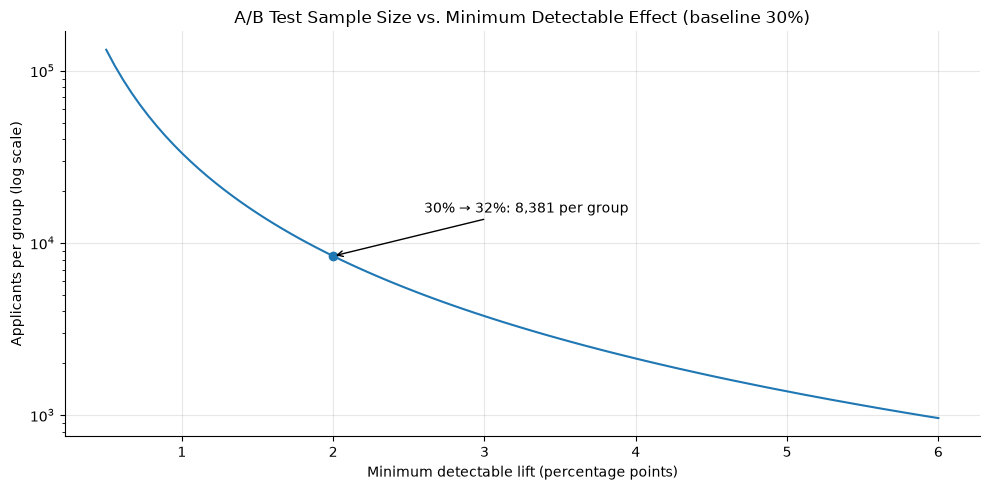

In [7]:
mde = np.linspace(0.005, 0.06, 100)
fig, ax = plt.subplots()
ax.plot(mde * 100, [sample_size(0.30, 0.30 + m) for m in mde])
ax.scatter([2], [sample_size(0.30, 0.32)], zorder=3)
ax.annotate("30% → 32%: 8,381 per group", (2, sample_size(0.30, 0.32)), xytext=(2.6, 15000),
            arrowprops={"arrowstyle": "->"})
ax.set_yscale("log")
ax.set_title("A/B Test Sample Size vs. Minimum Detectable Effect (baseline 30%)")
ax.set_xlabel("Minimum detectable lift (percentage points)")
ax.set_ylabel("Applicants per group (log scale)")
fig.tight_layout()
fig.savefig(IMAGE_DIR / "ab_sample_size.png", dpi=150)
plt.show()

* **Halving the detectable lift quadruples the sample** (1 pp: 33,234 per group), because the signal enters squared. The target lift should come from the business case: how much extra take-up the lower rate must buy to pay for itself.
* Take-up can be read after ~2 months; **risk guardrails need 6+ months** of performance.
* *Assumption: 10,000 grade-B offers a month; actual volume sets the duration.*

## 4. Next steps
* Fit a **logistic-regression scorecard** on the WOE features (development sample: Jan-2014 to Jun-2015) and evaluate on the out-of-time sample against `grade` (KS, AUC / Gini, calibration).
* Add a VIF check alongside the pairwise correlations.